# Day 7 · Correlation, WOE Transformation & A/B Test Sizing

*Work log: a cleaned version of my working notebook. The polished analysis lives in [`../07_correlation_woe_and_ab_test`](../07_correlation_woe_and_ab_test.ipynb).*

**Goals:** check the shortlisted features for multicollinearity, convert all eight to WOE for modeling, and size an A/B test for a grade-B price cut.

**Key results:** no feature pair has |ρ| > 0.7 (max 0.49, income vs. loan amount). All eight features are WOE-transformed with no missing values, and the IVs match Day 6. Detecting a 30% → 32% take-up lift needs 8,381 applicants per group (about 17,000 offers, ~2 months).

## 1. Setup

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = (Path.cwd().parents[1] / "Data").resolve()   # project_root/Data
con = duckdb.connect()

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
import numpy as np

In [2]:
# Rebuild the analysis views (DuckDB views are in-memory and reset every session)

# loans: every accepted loan
con.sql(f"""
CREATE OR REPLACE VIEW loans AS
SELECT *
FROM '{DATA}/accepted.parquet'
""")

# loans_clean: drop the 33 file-footer rows and parse the text issue date ('Dec-2015') into a real date
con.sql("""
CREATE OR REPLACE VIEW loans_clean AS
SELECT *,
       strptime(issue_d, '%b-%Y') AS issue_date
FROM loans
WHERE loan_status IS NOT NULL
""")

# cohort: 36-month loans issued 2014-2015, all matured by Dec-2018 so outcomes are final
con.sql("""
CREATE OR REPLACE VIEW cohort AS
SELECT *
FROM loans_clean
WHERE issue_date BETWEEN '2014-01-01' AND '2015-12-31'
  AND TRIM(term) = '36 months'
""")

# rejected: declined applications
con.sql(f"""
CREATE OR REPLACE VIEW rejected AS
SELECT *
FROM '{DATA}/rejected.parquet'
""")

con.sql("SHOW TABLES").df()

,name
0,cohort
1,loans
2,loans_clean
3,rejected


In [3]:
def calc_iv(df, bin_col):
    t = df.groupby(bin_col, observed=True, dropna=False)["bad_flag"].agg(n_bad="sum", n_total="count")
    t["n_good"]    = t["n_total"] - t["n_bad"]
    t["dist_good"] = t["n_good"] / t["n_good"].sum()
    t["dist_bad"]  = t["n_bad"] / t["n_bad"].sum()
    t["woe"]       = np.log(t["dist_good"] / t["dist_bad"])
    t["iv_bin"]    = (t["dist_good"] - t["dist_bad"]) * t["woe"]
    return t, t["iv_bin"].sum()

## 2. Correlation between numeric features
Spearman (rank-based) instead of Pearson, because the data has extreme values such as DTI = 999 and very high incomes.

In [4]:
num = con.sql("""
SELECT fico_range_low, annual_inc, dti, inq_last_6mths, revol_util, loan_amnt
FROM cohort
""").df()

corr = num.corr(method="spearman")     # method names are lower-case strings
corr.round(2)

,fico_range_low,annual_inc,dti,inq_last_6mths,revol_util,loan_amnt
fico_range_low,1.00,0.14,-0.01,-0.13,-0.35,0.18
annual_inc,0.14,1.00,-0.24,0.03,0.08,0.49
dti,-0.01,-0.24,1.00,0.01,0.15,-0.01
inq_last_6mths,-0.13,0.03,0.01,1.00,-0.08,-0.05
revol_util,-0.35,0.08,0.15,-0.08,1.00,0.10
loan_amnt,0.18,0.49,-0.01,-0.05,0.10,1.00


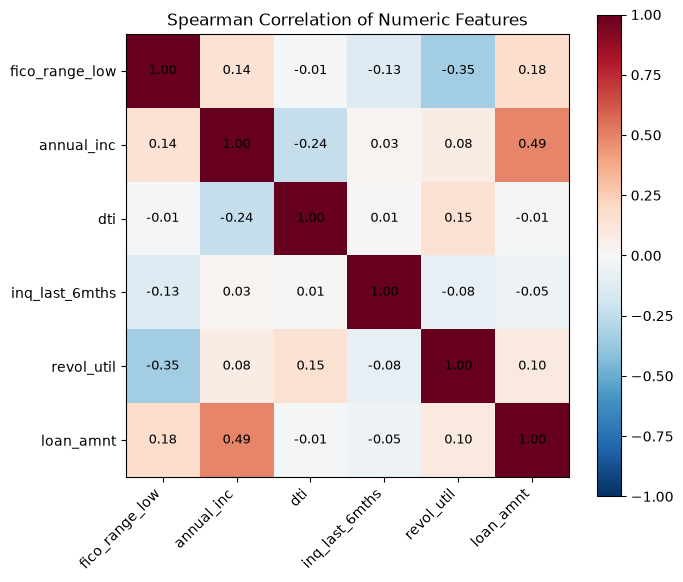

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)          # red = positive, blue = negative
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):                                     # write each coefficient in its cell
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im)
ax.set_title("Spearman Correlation of Numeric Features")
plt.tight_layout()
plt.show()

**Findings**
* No pair has an absolute correlation above 0.7, so there is no serious multicollinearity.
* Strongest pair: income vs. loan amount (+0.49), which makes sense, since higher earners can borrow more. Loan amount was already dropped for low IV.
* FICO's strongest link is with **revolving utilization (−0.35)**: judge strength by the **absolute value**. Utilization is part of the FICO formula, which explains its low IV.

## 3. WOE transformation of one feature (FICO)
Replace each loan's bin with that bin's WOE: `table["woe"]` works as a bin → WOE lookup for `.map()`.

In [6]:
df = con.sql("""
SELECT fico_range_low,
       CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
            WHEN loan_status = 'Fully Paid' THEN 0 END AS bad_flag
FROM cohort
""").df()

df["fico_bin"] = pd.qcut(df["fico_range_low"], 5, duplicates="drop")
table, iv = calc_iv(df, "fico_bin")
df["fico_woe"] = df["fico_bin"].map(table["woe"])

df.groupby("fico_woe").agg(
    n_loans=("bad_flag", "size"),      # named aggregation: (column name, function)
    bad_rate=("bad_flag", "mean"),
)

,n_loans,bad_rate
fico_woe,,
-0.356384,89931,0.194659
-0.222860,115024,0.174575
-0.009050,84595,0.145872
0.258307,76732,0.115607
0.779341,79461,0.072042


Higher WOE means a lower bad rate, monotonically (19.5% at WOE −0.36 down to 7.2% at +0.78). The bin with WOE ≈ 0 has a bad rate of 14.6%, almost exactly the portfolio average of 14.5%: WOE = 0 means "average risk".

## 4. WOE transformation of all eight shortlisted features

In [7]:
model = con.sql("""
SELECT issue_date, fico_range_low, annual_inc, dti, inq_last_6mths,
       home_ownership, verification_status, purpose, emp_length,
       CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
            WHEN loan_status = 'Fully Paid' THEN 0 END AS bad_flag
FROM cohort
""").df()

# Categorical clean-up (Day 4 and Day 6 rules)
model["emp_length"] = model["emp_length"].fillna("Missing")                         # missing is its own category
counts = model["purpose"].value_counts()
small = counts[counts < 300].index
model["purpose"] = model["purpose"].where(~model["purpose"].isin(small), "other")    # merge tiny purposes into 'other'
model["home_ownership"] = model["home_ownership"].replace("ANY", "RENT")            # 2 loans, conservative choice


def woe_transform(df, col):
    if col in ["fico_range_low", "annual_inc", "dti"]:
        df["bin"] = pd.qcut(df[col], 5, duplicates="drop").astype(str)   # astype(str) lets missing values map too
    elif col == "inq_last_6mths":
        df["bin"] = df[col].clip(upper=3)                                # 0 / 1 / 2 / 3+
    else:
        df["bin"] = df[col]                                              # categories are already bins
    table, iv = calc_iv(df, "bin")
    return df["bin"].map(table["woe"]), iv


features = ["fico_range_low", "annual_inc", "dti", "inq_last_6mths",
            "home_ownership", "verification_status", "purpose", "emp_length"]

for col in features:
    model[col + "_woe"], iv = woe_transform(model, col)
    print(f"{col:22s} IV = {iv:.4f}")

fico_range_low         IV = 0.1349


annual_inc             IV = 0.0619


dti                    IV = 0.0540
inq_last_6mths         IV = 0.0431
home_ownership         IV = 0.0439
verification_status    IV = 0.0401
purpose                IV = 0.0217
emp_length             IV = 0.0215


In [8]:
woe_cols = [c + "_woe" for c in features]      # list comprehension
print(model[woe_cols].isna().sum())             # should all be 0
model[woe_cols].describe().round(3)

fico_range_low_woe         0
annual_inc_woe             0
dti_woe                    0
inq_last_6mths_woe         0
home_ownership_woe         0
verification_status_woe    0
purpose_woe                0
emp_length_woe             0
dtype: int64


,fico_range_low_woe,annual_inc_woe,dti_woe,inq_last_6mths_woe,home_ownership_woe,verification_status_woe,purpose_woe,emp_length_woe
count,445743.0,445743.0,445743.0,445743.0,445743.0,445743.0,445743.0,445743.0
mean,0.052,0.022,0.019,0.015,0.016,0.014,0.008,0.007
std,0.394,0.249,0.23,0.202,0.211,0.201,0.146,0.139
min,-0.356,-0.343,-1.776,-0.471,-0.204,-0.247,-0.558,-0.458
25%,-0.223,-0.101,-0.119,-0.106,-0.204,-0.247,-0.06,-0.006
50%,-0.009,0.015,0.048,0.17,-0.07,-0.012,-0.06,0.005
75%,0.258,0.184,0.214,0.17,0.239,0.273,0.154,0.132
max,0.779,0.379,0.294,0.17,0.239,0.273,0.216,0.132


**Findings**
* IVs match Day 6 exactly and no loan is left without a WOE value: the model-ready table is done.
* Every WOE column has a negative minimum and a positive maximum: the overall bad rate is a weighted average, so some bins must be riskier than average and some safer.
* `dti_woe` has an extreme minimum of **−1.78**: the missing-DTI bin, only 2 loans. Tiny bins should be merged before modeling.
* **Errors I hit today:** `plt` and `np` not imported in the new notebook, `calc_iv` not yet defined, and the views lost after re-running `duckdb.connect()`. Fix: keep all imports in the first cell, and re-run setup cells top to bottom.

## 5. A/B test sample size
**Scenario:** cut APR by 1 point for grade B to raise take-up from 30% to 32%.

`n per group = (z_α/2 + z_β)² × [p₁(1−p₁) + p₂(1−p₂)] / (p₂ − p₁)²`, i.e. confidence × noise / signal.

In [9]:
def sample_size(p1, p2, z_alpha=1.96, z_beta=0.84):
    """Applicants needed per group to detect a change in a proportion from p1 to p2.
    z_alpha = 1.96: 5% significance (two-sided); z_beta = 0.84: 80% power.
    """
    variance = p1 * (1 - p1) + p2 * (1 - p2)        # noise: randomness in each applicant's decision
    effect   = (p2 - p1) ** 2                        # signal: the difference we want to detect, squared
    n = (z_alpha + z_beta) ** 2 * variance / effect
    return np.ceil(n)                                # round up: a fraction of a person is not enough


print(f"30% → 32%: {sample_size(0.30, 0.32):,.0f} per group")

for mde in [0.01, 0.02, 0.03, 0.05]:
    print(f"MDE {mde:.0%}: {sample_size(0.30, 0.30 + mde):,.0f} per group")

30% → 32%: 8,381 per group
MDE 1%: 33,234 per group
MDE 2%: 8,381 per group
MDE 3%: 3,756 per group
MDE 5%: 1,373 per group


**Findings**
* 30% → 32% needs **8,381 per group** (~17,000 offers): about **1.7 months** at 10,000 grade-B offers a month, so ~2 months in full months to cover seasonality.
* Halving the detectable lift (2 pp → 1 pp) **quadruples** the sample (33,234), because the signal enters squared.
* **Guardrails** (early delinquency, risk-adjusted return) are essential: a lower price gives up interest income and can attract more rate-sensitive, potentially riskier borrowers. They need 6+ months of performance.
* Design summary: H₀ no change in take-up; random 50/50 assignment at the offer; take-up as the primary metric; guardrails as above; a decision rule fixed before launch; segment review and a fair-lending check.